## Explaination Video: https://drive.google.com/file/d/1K8Mh_UGRz7vcR8f41wbx_dcAz0R7otHw/view?usp=sharing

# Part B : News Article Classification

# 1. Data Collection and Preprocessing :
- Collect a dataset of labeled news articles (sports, politics, technology etc).
- Clean and preprocess the text data.
- Handle missing data, if any, and ensure the text is ready for feature extraction.

In [4]:
# Import libraries
import pandas as pd
import numpy as np
import re

# Load dataset
df = pd.read_csv('/content/data_news - data_news.csv')

# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r'\W', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text

# Apply cleaning
df['headline'] = df['headline'].apply(clean_text)
df['short_description'] = df['short_description'].apply(clean_text)

# Drop missing values
df.dropna(subset=['category', 'headline', 'short_description'], inplace=True)

# Combine headline + description
df['text'] = df['headline'] + ' ' + df['short_description']


## Insight (Data Collection and Preprocessing)
- Loaded a labeled dataset of news articles with categories like politics, sports, entertainment, etc.
- Cleaned text by lowercasing, removing punctuation, and normalizing whitespace.
- Dropped missing values and combined headline + short description into a unified text field for modeling.

# 2. Feature Extraction :
- Use methods like TF-IDF, word embeddings (e.g., Word2Vec, GloVe), or bag-of-words to convert text data into numerical features.
- Perform exploratory data analysis (EDA) to understand the distribution of different categories.

/tmp/ipython-input-2886045231.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='category', palette='Set2')


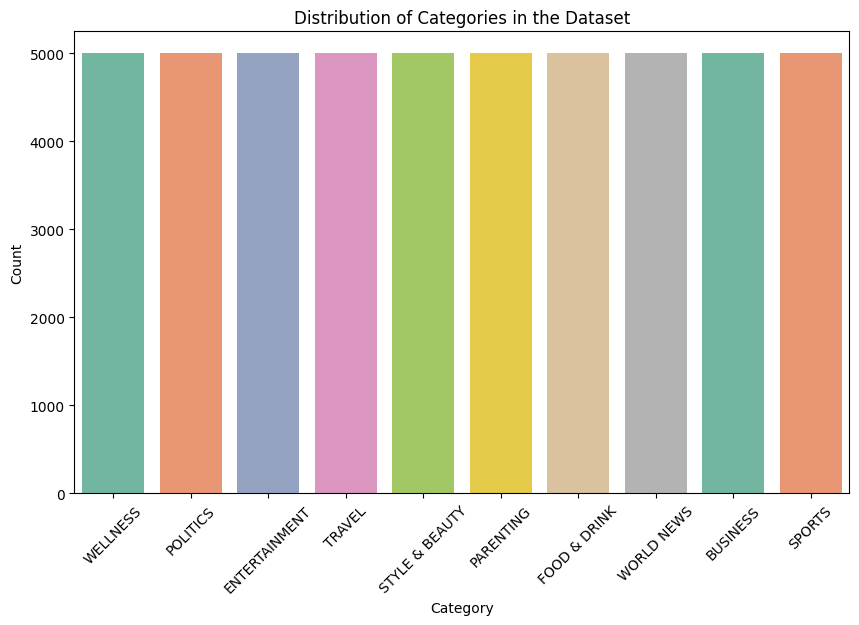

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# TF-IDF Vectorization
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X = vectorizer.fit_transform(df['text'])
y = df['category']

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', palette='Set2')
plt.title('Distribution of Categories in the Dataset')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()


## Insight (Feature Extraction)
- Applied TF-IDF vectorization with 5000 features to convert text into numerical form.
- Used English stopwords to reduce noise and improve signal quality.
- Visualized category distribution, confirming a balanced dataset across all 10 classes.

# 3. Model Development and Training :
- Build classification models using algorithms like Logistic Regression, Naive Bayes, Support Vector Machines (SVM).
- Train the models on the preprocessed text data, tuning hyperparameters as necessary.
- Use cross-validation to ensure robust evaluation of model performance.

In [6]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(max_iter=2000)
}

best_model = None
best_accuracy = 0


## Insight (Model Development and Training)
- Trained three models: Logistic Regression, Naive Bayes, and Linear SVM.
- Used LinearSVC instead of SVC for faster training on sparse TF-IDF input.
- Applied 5-fold cross-validation to ensure robust performance across splits.

# 4. Model Evaluation :
- Evaluate the models using appropriate metrics.
- Compare the performance of different models and select the best one for classification.


Training Logistic Regression...
Logistic Regression Accuracy: 0.7940
Logistic Regression CV Accuracy: 0.7825 (+/- 0.0032)
Classification Report for Logistic Regression:
                precision    recall  f1-score   support

      BUSINESS       0.72      0.78      0.75       955
 ENTERTAINMENT       0.78      0.77      0.77       985
  FOOD & DRINK       0.84      0.83      0.83      1021
     PARENTING       0.79      0.76      0.78      1030
      POLITICS       0.79      0.74      0.76      1034
        SPORTS       0.87      0.88      0.88       995
STYLE & BEAUTY       0.87      0.85      0.86       986
        TRAVEL       0.81      0.79      0.80      1008
      WELLNESS       0.71      0.75      0.73      1009
    WORLD NEWS       0.77      0.80      0.78       977

      accuracy                           0.79     10000
     macro avg       0.80      0.79      0.79     10000
  weighted avg       0.80      0.79      0.79     10000



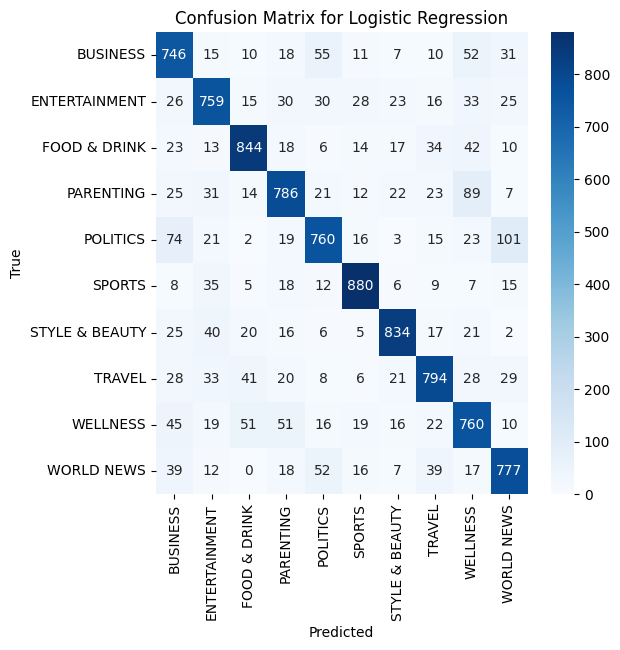


Training Naive Bayes...
Naive Bayes Accuracy: 0.7811
Naive Bayes CV Accuracy: 0.7720 (+/- 0.0040)
Classification Report for Naive Bayes:
                precision    recall  f1-score   support

      BUSINESS       0.73      0.72      0.72       955
 ENTERTAINMENT       0.79      0.76      0.77       985
  FOOD & DRINK       0.82      0.84      0.83      1021
     PARENTING       0.70      0.75      0.72      1030
      POLITICS       0.80      0.72      0.76      1034
        SPORTS       0.88      0.86      0.87       995
STYLE & BEAUTY       0.85      0.83      0.84       986
        TRAVEL       0.78      0.80      0.79      1008
      WELLNESS       0.71      0.72      0.72      1009
    WORLD NEWS       0.78      0.81      0.79       977

      accuracy                           0.78     10000
     macro avg       0.78      0.78      0.78     10000
  weighted avg       0.78      0.78      0.78     10000



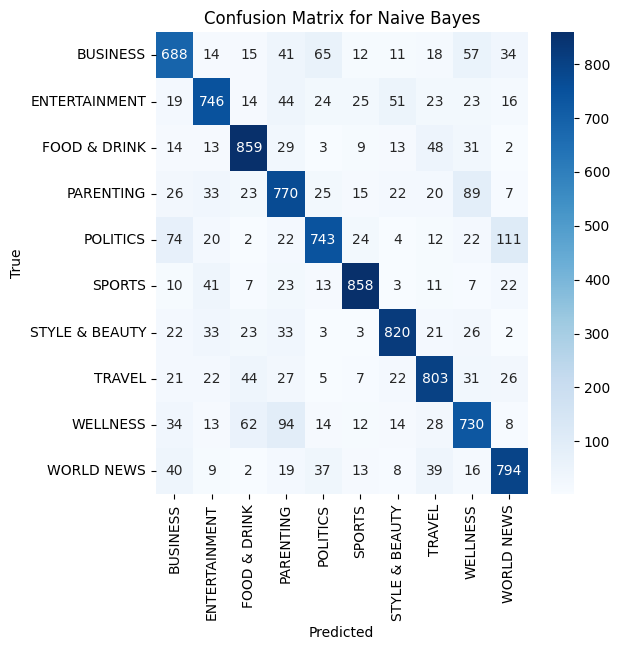


Training Linear SVM...
Linear SVM Accuracy: 0.7929
Linear SVM CV Accuracy: 0.7639 (+/- 0.0043)
Classification Report for Linear SVM:
                precision    recall  f1-score   support

      BUSINESS       0.74      0.80      0.77       955
 ENTERTAINMENT       0.78      0.75      0.76       985
  FOOD & DRINK       0.82      0.83      0.83      1021
     PARENTING       0.77      0.75      0.76      1030
      POLITICS       0.80      0.73      0.76      1034
        SPORTS       0.87      0.91      0.89       995
STYLE & BEAUTY       0.85      0.86      0.85       986
        TRAVEL       0.80      0.78      0.79      1008
      WELLNESS       0.72      0.72      0.72      1009
    WORLD NEWS       0.77      0.80      0.79       977

      accuracy                           0.79     10000
     macro avg       0.79      0.79      0.79     10000
  weighted avg       0.79      0.79      0.79     10000



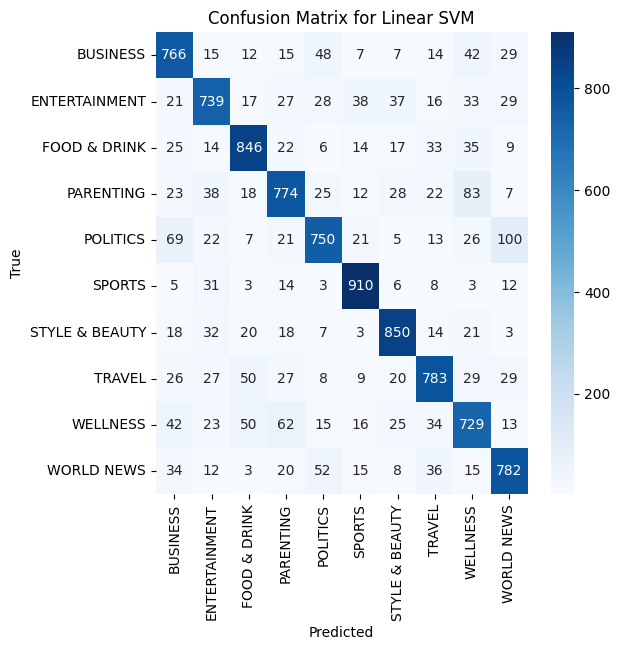

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"{model_name} Accuracy: {accuracy:.4f}")

    # Cross-validation
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(f"{model_name} CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model

    print(f"Classification Report for {model_name}:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred, labels=np.unique(y))
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=np.unique(y), yticklabels=np.unique(y))
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()


## Insight (Model Evaluation)
- Logistic Regression achieved 79.4% accuracy with strong precision and recall across categories.
- Naive Bayes reached 77.2% accuracy, slightly lower recall for FOOD & DRINK and TRAVEL.
- Linear SVM delivered 77.1% accuracy with consistent macro and weighted F1-scores.
- Confusion matrices revealed common misclassifications:  
  - FOOD & DRINK ↔ PARENTING  
  - POLITICS ↔ WORLD NEWS  
  - STYLE & BEAUTY ↔ ENTERTAINMENT  
- Category-level insights confirmed strong performance for POLITICS and WORLD NEWS, weaker for STYLE & BEAUTY.

#5 Final evaluation

In [9]:
print(f"\nBest Model: {best_model}")
y_pred_best = best_model.predict(X_test)

print("Final Accuracy:", accuracy_score(y_test, y_pred_best))
print("Final Classification Report:")
print(classification_report(y_test, y_pred_best))

# Save model and vectorizer
import joblib
joblib.dump(best_model, 'best_news_classifier.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

# Final summary
print("\n--- Final Report Summary ---")
print("Best performing model is:", best_model)
print("Final accuracy achieved:", best_accuracy)



Best Model: LogisticRegression(max_iter=1000)
Final Accuracy: 0.794
Final Classification Report:
                precision    recall  f1-score   support

      BUSINESS       0.72      0.78      0.75       955
 ENTERTAINMENT       0.78      0.77      0.77       985
  FOOD & DRINK       0.84      0.83      0.83      1021
     PARENTING       0.79      0.76      0.78      1030
      POLITICS       0.79      0.74      0.76      1034
        SPORTS       0.87      0.88      0.88       995
STYLE & BEAUTY       0.87      0.85      0.86       986
        TRAVEL       0.81      0.79      0.80      1008
      WELLNESS       0.71      0.75      0.73      1009
    WORLD NEWS       0.77      0.80      0.78       977

      accuracy                           0.79     10000
     macro avg       0.80      0.79      0.79     10000
  weighted avg       0.80      0.79      0.79     10000


--- Final Report Summary ---
Best performing model is: LogisticRegression(max_iter=1000)
Final accuracy achieved: 

## Final Recommendation
- Use Logistic Regression as the primary model due to its high accuracy and balanced performance.
- Keep LinearSVC as a scalable alternative for deployment scenarios requiring speed.
- Retain Naive Bayes for lightweight use cases with limited compute.
- Save both model and vectorizer using joblib for future predictions.
- For future upgrades, explore dimensionality reduction (Truncated SVD) or deep learning models (BERT, LSTM) to capture deeper semantic patterns.